In [1]:
# run from mudata environment

import os
import sys
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
import session_info
import muon as mu
from muon import MuData
from muon import atac as ac

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from single_cell_utils import *
from scjp_colors import *

In [2]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/mdata/tf_pilot/batch1/ipsc/'
os.makedirs(work_dir , exist_ok=True)

In [3]:
sc.settings.verbosity = 0             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_header()
sc.settings.set_figure_params(dpi=80, facecolor='white')

scanpy==1.9.6 anndata==0.9.2 umap==0.5.7 numpy==1.24.4 scipy==1.10.1 pandas==2.0.3 scikit-learn==1.3.2 statsmodels==0.14.1 igraph==0.10.8 pynndescent==0.5.13


In [4]:
import project_style_py as scp
scp.load_project_palettes('/lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_palettes.yaml'
)
scp.load_project_themes(
    '/lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_themes_py.yaml'
)

import matplotlib as mpl

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Helvetica"]
mpl.rcParams["pdf.fonttype"] = 42   # keeps text editable in Illustrator
mpl.rcParams["ps.fonttype"] = 42

Successfully loaded palettes from: /software/conda/users/od5/bin2cell/lib/python3.8/site-packages/project_style_py/resources/palettes.yaml
Successfully loaded themes from: /software/conda/users/od5/bin2cell/lib/python3.8/site-packages/project_style_py/resources/themes.yaml
Successfully loaded palettes from: /lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_palettes.yaml
Successfully loaded themes from: /lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_themes_py.yaml
Loading fonts for theme: default
Font saved to temporary file: /tmp/tmpp2y930uo.ttf
Font saved to temporary file: /tmp/tmp3cubrqhj.ttf
Font saved to temporary file: /tmp/tmpi80264wi.ttf
Font saved to temporary file: /tmp/tmpbph7o49p.ttf
Loading fonts for theme: theme_bw
Font saved to temporary file: /tmp/tmpk_a38njr.ttf
Font saved to temporary file: /tmp/tmpl_u_xa0r.ttf
Font saved to temporary file: /tmp/tmpje3854r4.ttf
F

## Load data

In [5]:
## Read mdata object
mdata = mu.read_h5mu((work_dir + 'mdata_full.h5mu'))

In [6]:
mdata

MuData object with n_obs × n_vars = 6192 × 118951
  2 modalities
    rna:	6192 x 36601
      obs:	'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5', 'v3_leiden_1', 'v3_leiden_0.9', 'v3_leiden_0.8'
      var:	'highly_variable', 'means', 'dispersions', 'dispersions_norm'
      uns:	'amulet_doublet_colors', 'anno_v1_nuc_gex_colors', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'perturbation_colors', 'rank_genes_groups', 'sample_ID_colors', 'sample_description_colors', 'umap', 'v1_leiden_100', 'v2_leiden_1.5', 'v2_leiden_1.5_colors', 'v3_leiden_0.8', 'v3_leiden_0.8_colors', 'v3_leiden_0.9', 'v3_leiden_0.9_colors', 'v3_leiden_1', 'v3_leiden_1.5', 'v3_leiden_1.5_colors', 'v3_leiden_1_colors'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    atac:	6192 x 82350
      obs:	'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5', 'v3_leiden_1', 'v3_leiden_0.9', 'v3_leiden_0.8'

In [8]:
# # Add obs from RNA to ATAC
# mdata['atac'].obs = mdata['rna'].obs

In [9]:
# mdata

/software/conda/users/od5/bin2cell/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


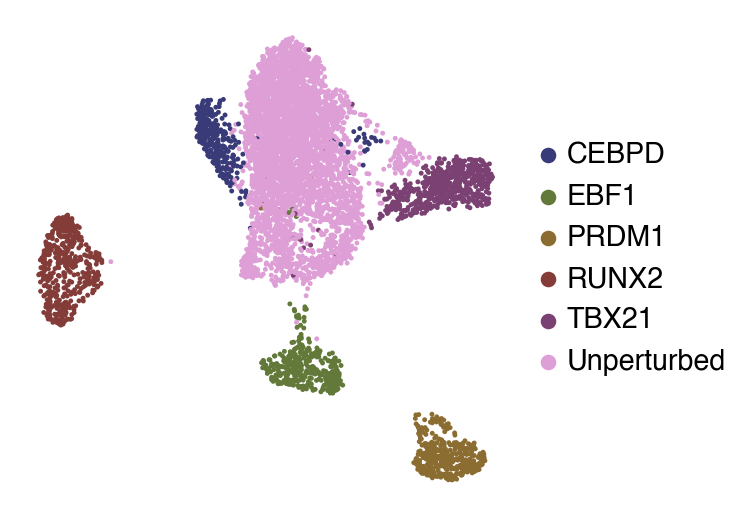

In [10]:
sc.pl.umap(mdata['rna'], color = 'anno_v1_nuc_gex', title = '', frameon = False, palette='tab20b')

/software/conda/users/od5/bin2cell/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


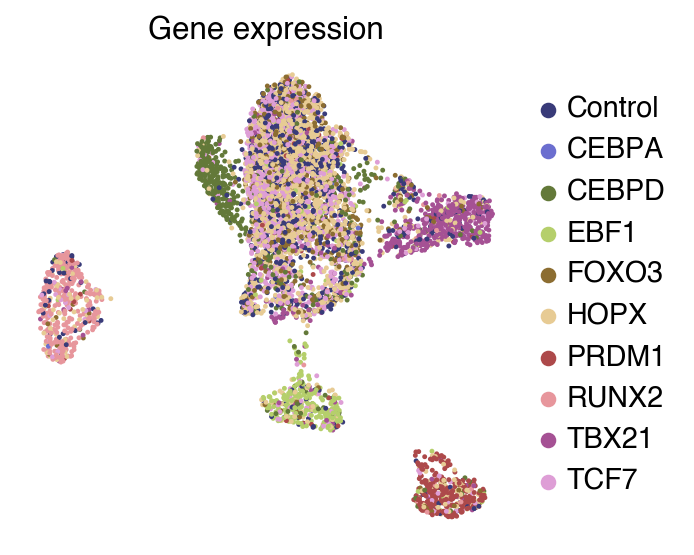

In [11]:
sc.pl.umap(mdata['rna'], color = 'perturbation', title = 'Gene expression', frameon = False, palette='tab20b', show=False)

plt.savefig("ipsc_multiome_gex_umap.pdf", bbox_inches="tight")
plt.show()

In [20]:
# ATAC
atac = mdata['atac']

/software/conda/users/od5/bin2cell/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


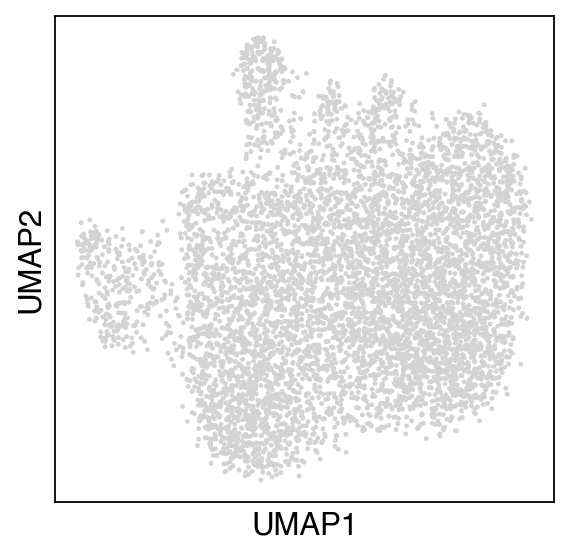

In [21]:
# Compute LSI for ATAC data

# Optional but common: remove features detected in very few cells
# sc.pp.filter_genes(atac, min_cells=10)

# TF-IDF normalization
mu.atac.pp.tfidf(atac)

# LSI = truncated SVD on TF-IDF matrix
mu.atac.tl.lsi(atac)

# Use LSI for neighbors and UMAP
sc.pp.neighbors(atac, use_rep="X_lsi")
sc.tl.umap(atac)

# Plot
sc.pl.umap(atac)

/software/conda/users/od5/bin2cell/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


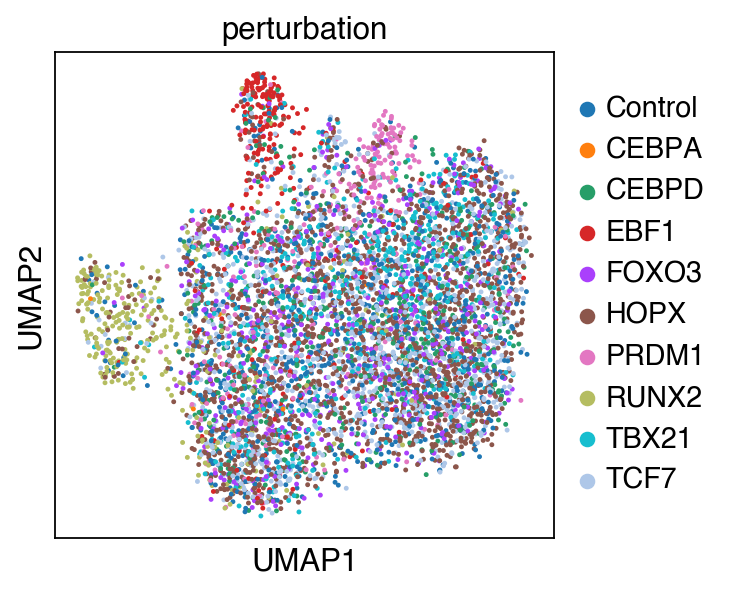

In [22]:
sc.pl.umap(atac, color='perturbation')

Spearman correlation between LSI1 and ATAC counts: rho=-0.994, p=0.00e+00


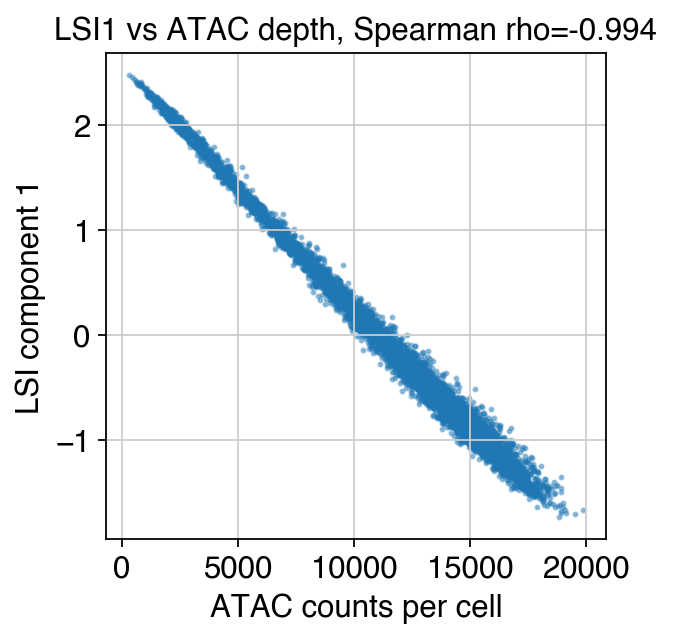

In [23]:
# Check whether LSI component 1 is dominated by sequencing depth

from scipy.stats import spearmanr

# Total counts/fragments per cell
atac.obs["atac_counts"] = np.asarray(atac.X.sum(axis=1)).ravel()

# First LSI component
lsi1 = atac.obsm["X_lsi"][:, 0]

# Spearman correlation
rho, pval = spearmanr(lsi1, atac.obs["atac_counts"])

print(f"Spearman correlation between LSI1 and ATAC counts: rho={rho:.3f}, p={pval:.2e}")

# Scatter plot
plt.scatter(atac.obs["atac_counts"], lsi1, s=3, alpha=0.4)
plt.xlabel("ATAC counts per cell")
plt.ylabel("LSI component 1")
plt.title(f"LSI1 vs ATAC depth, Spearman rho={rho:.3f}")
plt.show()

Spearman correlation between LSI2 and ATAC counts: rho=-0.461, p=0.00e+00


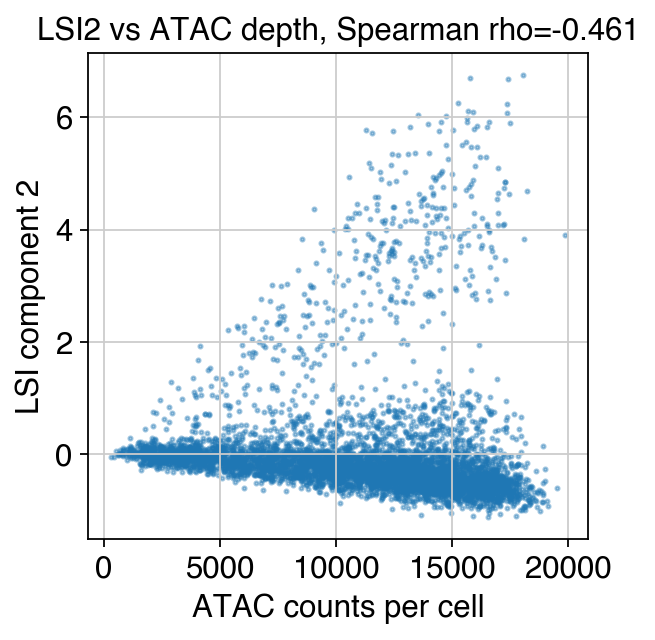

In [24]:
# Check whether LSI component 1 is dominated by sequencing depth


# Second LSI component
lsi2 = atac.obsm["X_lsi"][:, 1]

# Spearman correlation
rho, pval = spearmanr(lsi2, atac.obs["atac_counts"])

print(f"Spearman correlation between LSI2 and ATAC counts: rho={rho:.3f}, p={pval:.2e}")

# Scatter plot
plt.scatter(atac.obs["atac_counts"], lsi2, s=3, alpha=0.4)
plt.xlabel("ATAC counts per cell")
plt.ylabel("LSI component 2")
plt.title(f"LSI2 vs ATAC depth, Spearman rho={rho:.3f}")
plt.show()

/software/conda/users/od5/bin2cell/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


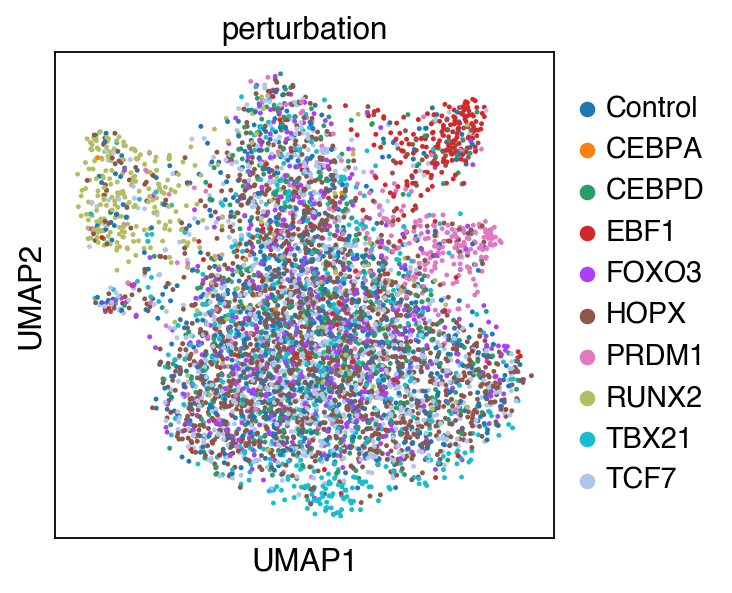

In [25]:
# Drop first LSI component manually
atac.obsm["X_lsi_use"] = atac.obsm["X_lsi"][:, 1:30]

sc.pp.neighbors(atac, use_rep="X_lsi_use")
sc.tl.umap(atac)
sc.pl.umap(atac, color="perturbation")

/software/conda/users/od5/bin2cell/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


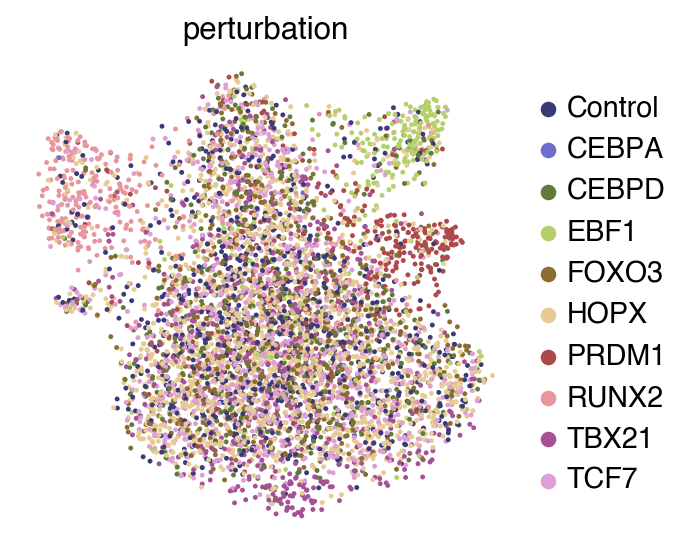

In [26]:
# Copy categorical colors too
atac.uns["perturbation_colors"] = mdata["rna"].uns["perturbation_colors"]

sc.pl.umap(atac, color="perturbation", frameon=False)

/software/conda/users/od5/bin2cell/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


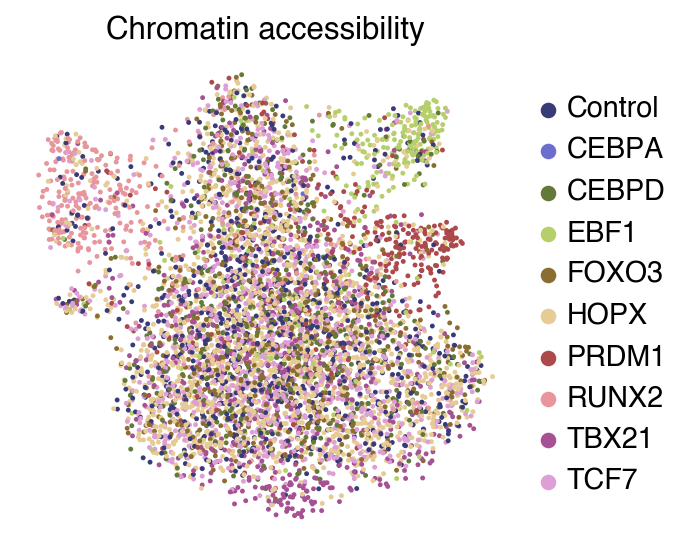

In [27]:
sc.pl.umap(atac, color = 'perturbation', title = 'Chromatin accessibility', frameon = False, palette='tab20b', show=False)

plt.savefig("ipsc_multiome_atac_umap.pdf", bbox_inches="tight")
plt.show()

In [28]:
dars = pd.read_csv('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/archr_DARs_perturbation_df.txt', sep='\t')

In [31]:
dars['Cell_type'].value_counts()

Cell_type
RUNX2    750
TBX21      3
CEBPD      1
Name: count, dtype: int64

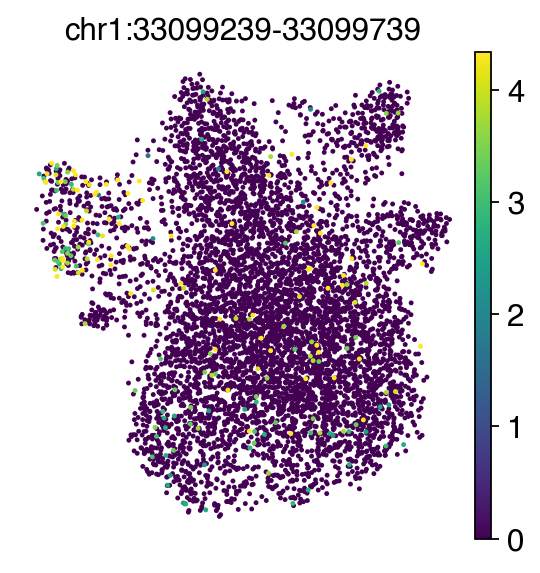

In [36]:
sc.pl.umap(atac, color = 'chr1:33099239-33099739', frameon = False, vmax='p99')

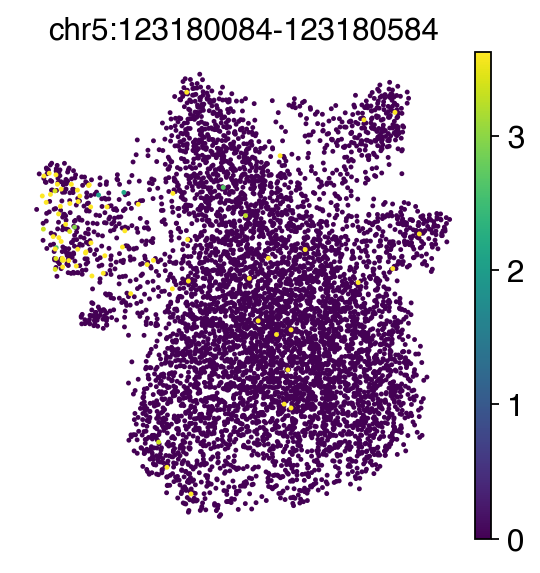

In [37]:
sc.pl.umap(atac, color = 'chr5:123180084-123180584', frameon = False, vmax='p99')

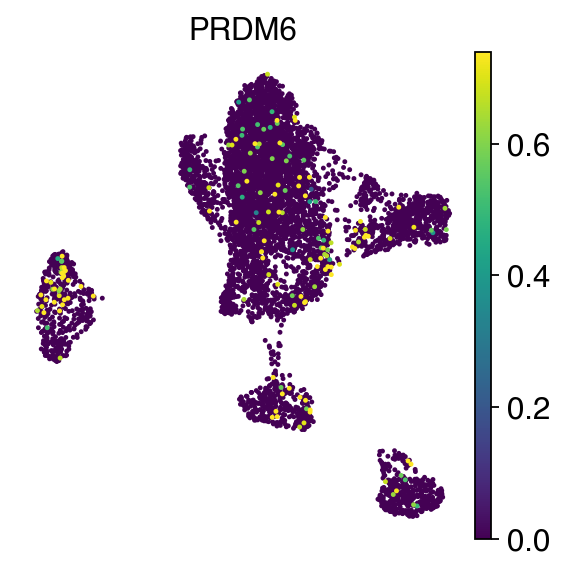

In [38]:
sc.pl.umap(mdata['rna'], color = 'PRDM6', frameon = False, vmax='p99')

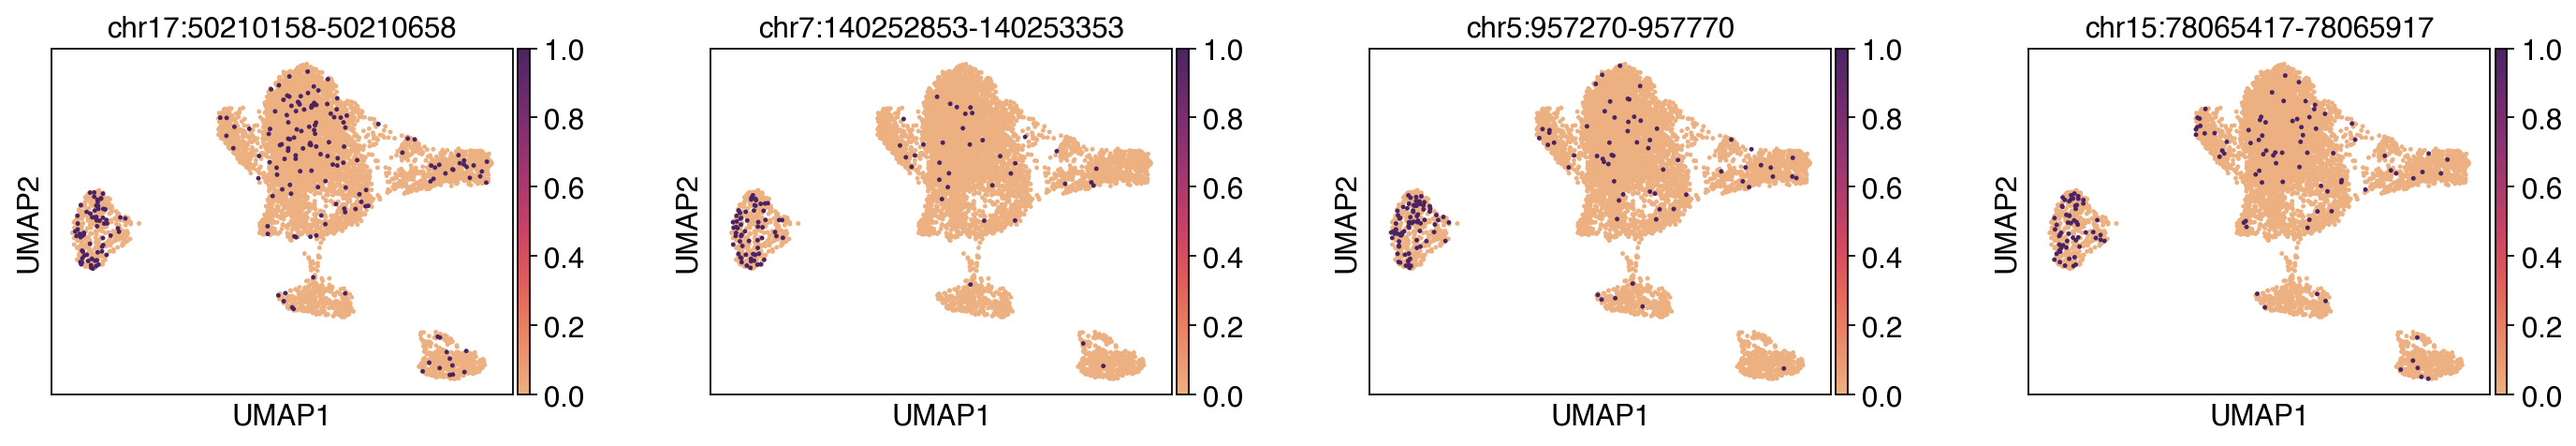

In [19]:
sc.set_figure_params(figsize=(4, 3))

peaks = [
    "chr17:50210158-50210658",
    "chr7:140252853-140253353",
    "chr5:957270-957770",
    "chr15:78065417-78065917",
]

rna = mdata["rna"]
atac = mdata["atac"]

for peak in peaks:
    values = atac[:, peak].X
    if hasattr(values, "toarray"):
        values = values.toarray().ravel()
    else:
        values = np.asarray(values).ravel()

    rna.obs[peak] = values

sc.pl.umap(
    rna,
    color=peaks,
    cmap="flare",
    vmax='p99.5',
    show=False,
    wspace=0.3
)
plt.savefig("multiome_atac_umaps.pdf", bbox_inches="tight")